# Multilayer nanoindentation: Au / Ti / SiO2 / Si

Analyze the bundled three-film CSM example using the NIMS Mercier multilayer elastic model. The notebook calculates sample hardness, fits the top-film modulus, estimates pointwise film modulus and hardness, and plots film hardness against sample hardness. The lower-film and substrate properties must be known independently; one indentation curve does not identify all layers simultaneously.

Run from the repository root or this notebook's folder. Requirements: Python 3, NumPy, SciPy, Matplotlib, and PyYAML. Units: displacement and thickness in nm, load in mN, stiffness in N/m in the input and mN/nm internally, and moduli and hardness in GPa.

This reproduces the current MATLAB equations and selected corrections, not every GUI setting. The historic YAML result used below was produced with different calibration and correction settings, so its fitted modulus is not a target for this run.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import least_squares
import yaml

cwd = Path.cwd().resolve()
root = next((p for p in (cwd, *cwd.parents) if (p / 'data_indentation').is_dir() and (p / 'matlab_code').is_dir()), None)
if root is None:
    raise FileNotFoundError('Start Jupyter in the NIMS repository or one of its subdirectories.')
data_dir = root / 'data_indentation'
data_file = data_dir / 'MTS_3films_Au-Ti-SiO2-Si_CSM-1nm.txt'
reference_file = data_dir / 'MTS_3films_Au-Ti-SiO2-Si_CSM-1nm.xls_Mercier&al..yaml'
abaqus_script = data_dir / 'MTS_3films_Au-Ti-SiO2-Si_CSM-1nm.py'
print('Repository:', root)

Repository: C:\github\NIMS


## Inputs

The example properties and 60–360 nm range follow the historic YAML export; substrate properties follow the accompanying FEM example. The Berkovich area function, diamond properties and correction constants follow the current NIMS configuration. Frame compliance is assumed to be zero. Layer order is **substrate to surface**; the top modulus is fitted, not an input. Inspect calibration, material properties and depth range before interpreting results.

In [2]:
depth_min_nm, depth_max_nm = 60.0, 360.0
substrate = {'name': 'Si', 'E_GPa': 165.0, 'nu': 0.28}
films = [
    {'name': 'SiO2', 'thickness_nm': 500.0, 'E_GPa': 70.0, 'nu': 0.18},
    {'name': 'Ti',   'thickness_nm': 500.0, 'E_GPa': 120.0, 'nu': 0.34},
    {'name': 'Au',   'thickness_nm': 500.0, 'E_GPa': None, 'nu': 0.32},
]
indenter_E_GPa, indenter_nu = 1070.0, 0.07
beta = 1.034
area_coefficients = [24.56, 0, 0, 0, 0, 0, 0, 0, 0]
tip_defect_nm = 1.0
loubet_alpha = 1.24
apply_csm_correction = True
csm_k, csm_m = 0.757, 1.38
thickness_correction_factor = 0.3  # Set to 0 to disable.
fit_initial_reduced_GPa = 100.0
fit_bounds_reduced_GPa = (1e-6, 1000.0)

## Loading data and contact quantities

The six columns are depth, depth SD, load, load SD, stiffness, and stiffness SD. We retain the loading branch through its first peak load, then select the open depth interval, as in NIMS. Its optional Pharr CSM correction uses the supplied standard deviations; enable it only when appropriate for the instrument and data.

In [3]:
raw = np.loadtxt(data_file, ndmin=2)
if raw.shape[1] != 6 or not np.isfinite(raw).all():
    raise ValueError('Expected six finite MTS columns.')
if not 0 <= depth_min_nm < depth_max_nm:
    raise ValueError('Depth limits must be nonnegative and increasing.')
raw = raw[:np.argmax(raw[:, 2]) + 1]
selected = raw[(raw[:, 0] > depth_min_nm) & (raw[:, 0] < depth_max_nm)]
if selected.shape[0] < 4:
    raise ValueError('At least four loading samples must lie in the depth range.')
depth, depth_sd, load, load_sd, stiffness_N_m, stiffness_sd = selected.T
stiffness = stiffness_N_m * 1e-6
if np.any(stiffness <= 0) or np.any(load <= 0):
    raise ValueError('Selected load and stiffness must be positive.')
if apply_csm_correction:
    if np.any(depth_sd <= 0) or csm_k <= 0 or csm_m <= 0:
        raise ValueError('CSM correction requires positive depth SD and correction constants.')
    peak_load = load.max()
    radicand = 1 - 2 * np.sqrt(2) * depth_sd * stiffness / peak_load
    if np.any(radicand < 0):
        raise ValueError('CSM correction is not real for the selected data.')
    stiffness = ((1 / np.sqrt(2 * np.pi)) * (1 / csm_k) ** (1 / csm_m)
                 * (1 - radicand ** (1 / csm_m)) * peak_load / depth_sd)
    depth = depth + np.sqrt(2) * depth_sd
    load = load + np.sqrt(2) * load_sd
if np.any(~np.isfinite(stiffness) | (stiffness <= 0)):
    raise ValueError('Corrected stiffness must be finite and positive.')

contact_depth = loubet_alpha * (depth + tip_defect_nm - load / stiffness)
if np.any(~np.isfinite(contact_depth) | (contact_depth <= 0)):
    raise ValueError('Contact depth must be finite and positive; check inputs and depth range.')
powers = [2, 1, 1/2, 1/4, 1/8, 1/16, 1/32, 1/64, 1/128]
if len(area_coefficients) != len(powers):
    raise ValueError('The area function requires nine coefficients.')
area = sum(c * contact_depth ** power for c, power in zip(area_coefficients, powers))
if np.any(~np.isfinite(area) | (area <= 0)) or beta <= 0:
    raise ValueError('Contact area and beta must be finite and positive.')
radius = np.sqrt(area / np.pi)
sample_hardness = 1e6 * load / area
print(f'{len(depth)} loading samples selected; contact depth {contact_depth.min():.2f}–{contact_depth.max():.2f} nm')

21 loading samples selected; contact depth 76.24–389.10 nm


## Reduced modulus and Mercier multilayer fit

NIMS's `indenter_properties.m` passes the square of the indenter Poisson ratio to `reduced_YM`, which squares it again. The modulus calculation below deliberately retains that legacy behavior for comparison. The pointwise top-film modulus is obtained by inverting the same multilayer compliance equation; nonpositive or nonfinite inversions are excluded, not treated as physical measurements.

In [4]:
def reduced_modulus(young, poisson):
    if not np.isfinite(young) or young <= 0 or not -1 < poisson < 0.5:
        raise ValueError('Young modulus must be positive and Poisson ratio must be between -1 and 0.5.')
    return young / (1 - poisson ** 2)

def multilayer_terms(contact_radius, contact_depth_nm, layers, base, correction):
    if len(layers) not in (2, 3):
        raise ValueError('The NIMS multilayer model requires two or three films.')
    if not np.isfinite(correction) or correction < 0:
        raise ValueError('Thickness correction factor must be finite and nonnegative.')
    a = np.asarray(contact_radius, dtype=float)
    hc = np.asarray(contact_depth_nm, dtype=float)
    if a.shape != hc.shape or np.any(~np.isfinite(a) | (a <= 0)) or np.any(~np.isfinite(hc) | (hc <= 0)):
        raise ValueError('Contact radii and depths must be matching positive arrays.')
    substrate_E = reduced_modulus(base['E_GPa'], base['nu'])
    lower_compliance = np.zeros_like(a)
    for index in range(len(layers) - 1, -1, -1):
        layer = layers[index]
        nominal = layer['thickness_nm']
        if not np.isfinite(nominal) or nominal <= 0:
            raise ValueError('All film thicknesses must be finite and positive.')
        thickness = nominal - correction * hc if index == len(layers) - 1 else nominal
        if np.any(thickness <= 0):
            raise ValueError('Corrected top-film thickness must remain positive.')
        coefficient = thickness / (np.pi * a ** 2 + 2 * a * thickness)
        if index == len(layers) - 1:
            top_coefficient = coefficient
            reduced_modulus(1.0, layer['nu'])
        else:
            lower_compliance += coefficient / reduced_modulus(layer['E_GPa'], layer['nu'])
        a = a + 2 * nominal / np.pi
    lower_compliance += 1 / (2 * a * substrate_E)
    return top_coefficient, lower_compliance

def composite_modulus(top_reduced, contact_radius, top_coefficient, lower_compliance):
    return 1 / (2 * contact_radius * (top_coefficient / top_reduced + lower_compliance))

indenter_reduced_legacy = reduced_modulus(indenter_E_GPa, indenter_nu ** 2)
effective_modulus = np.sqrt(np.pi) * 1e6 * stiffness / (2 * beta * np.sqrt(area))
sample_compliance = 1 / effective_modulus - 1 / indenter_reduced_legacy
if np.any(~np.isfinite(sample_compliance) | (sample_compliance <= 0)):
    raise ValueError('Invalid sample reduced modulus; check calibration and depth range.')
sample_reduced = 1 / sample_compliance
top_coefficient, lower_compliance = multilayer_terms(radius, contact_depth, films, substrate, thickness_correction_factor)
fit = least_squares(
    lambda p: composite_modulus(p[0], radius, top_coefficient, lower_compliance) - sample_reduced,
    [fit_initial_reduced_GPa], bounds=fit_bounds_reduced_GPa,
)
if not fit.success:
    raise RuntimeError(f'Mercier modulus fit failed: {fit.message}')
fitted_top_reduced = fit.x[0]
fitted_top_young = fitted_top_reduced * (1 - films[-1]['nu'] ** 2)
fitted_composite = composite_modulus(fitted_top_reduced, radius, top_coefficient, lower_compliance)
inverse_compliance = 1 / (2 * radius * sample_reduced) - lower_compliance
valid_film = np.isfinite(inverse_compliance) & (inverse_compliance > 0)
film_reduced = np.full_like(sample_reduced, np.nan)
film_reduced[valid_film] = top_coefficient[valid_film] / inverse_compliance[valid_film]
if not np.all(valid_film):
    warnings.warn(f'Excluded {np.count_nonzero(~valid_film)} nonphysical pointwise film-modulus estimates.')
print(f"Fitted {films[-1]['name']} Young modulus: {fitted_top_young:.2f} GPa (reduced: {fitted_top_reduced:.2f} GPa)")
print(f'Fit RMSE: {np.sqrt(np.mean(fit.fun ** 2)):.3f} GPa; {fit.message}')

Fitted Au Young modulus: 93.61 GPa (reduced: 104.29 GPa)
Fit RMSE: 1.391 GPa; `ftol` termination condition is satisfied.


## Film hardness

The first curve reproduces the formula in `model_mercier.m`: it converts the indenter reduced modulus from Pa using `1e-3` in a calculation otherwise expressed in GPa. This makes the indenter compliance almost negligible. The second curve uses the dimensionally consistent diamond reduced modulus, $E_i/(1-\nu_i^2)$ in GPa. It is included to expose the discrepancy, not as an independently validated replacement. Both use the same NIMS-compatible film modulus above and depend on the assumed lower layers.

Unlike the current MATLAB multilayer hardness workflow, which calls the bilayer elastic calculation, this notebook supplies the pointwise **multilayer** modulus to the hardness formula. Its film-hardness results therefore should not be assumed identical to the GUI.

In [5]:
indenter_reduced_physical = reduced_modulus(indenter_E_GPa, indenter_nu)
legacy_effective_film = 1 / (1 / film_reduced + 1 / (indenter_reduced_legacy * 1e6))
physical_effective_film = 1 / (1 / film_reduced + 1 / indenter_reduced_physical)
hardness_factor = beta ** 2 * (4 / np.pi) * load / (1e6 * stiffness ** 2)
film_hardness_nims = hardness_factor * legacy_effective_film ** 2
film_hardness_corrected = hardness_factor * physical_effective_film ** 2
if not np.any(np.isfinite(film_hardness_nims)):
    raise ValueError('No valid pointwise film-hardness estimates remain.')
print(f'Mean sample hardness: {np.mean(sample_hardness):.2f} GPa')
print(f'Mean film hardness, NIMS-compatible: {np.nanmean(film_hardness_nims):.2f} GPa')
print(f'Mean film hardness, corrected indenter units: {np.nanmean(film_hardness_corrected):.2f} GPa')

Mean sample hardness: 2.19 GPa
Mean film hardness, NIMS-compatible: 1.84 GPa
Mean film hardness, corrected indenter units: 1.53 GPa


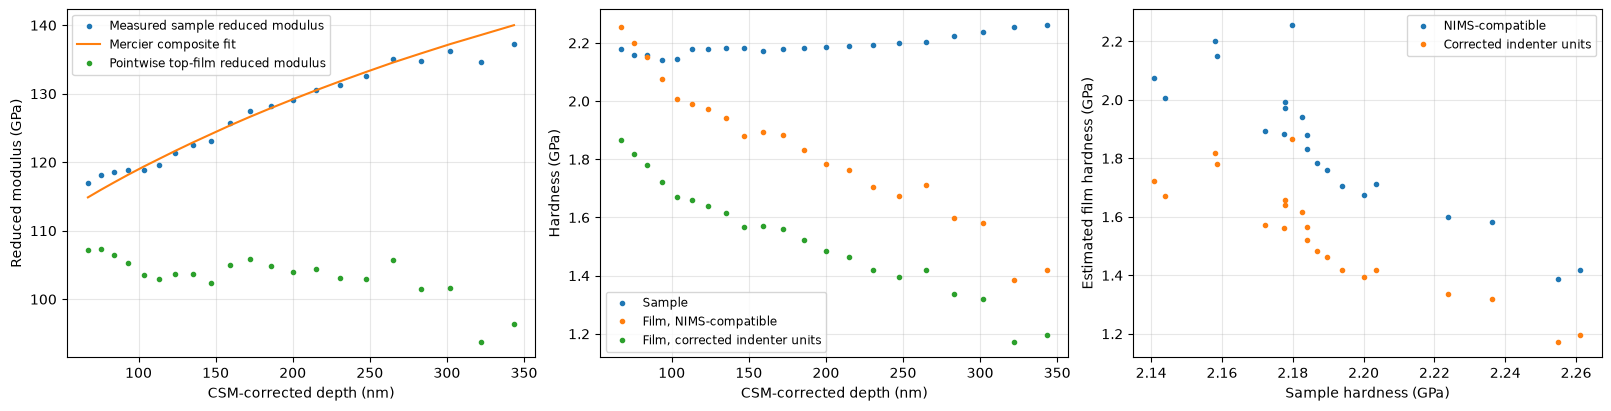

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(depth, sample_reduced, '.', label='Measured sample reduced modulus')
axes[0].plot(depth, fitted_composite, '-', label='Mercier composite fit')
axes[0].plot(depth, film_reduced, '.', label='Pointwise top-film reduced modulus')
depth_label = 'CSM-corrected depth (nm)' if apply_csm_correction else 'Depth (nm)'
axes[0].set(xlabel=depth_label, ylabel='Reduced modulus (GPa)')
axes[1].plot(depth, sample_hardness, '.', label='Sample')
axes[1].plot(depth, film_hardness_nims, '.', label='Film, NIMS-compatible')
axes[1].plot(depth, film_hardness_corrected, '.', label='Film, corrected indenter units')
axes[1].set(xlabel=depth_label, ylabel='Hardness (GPa)')
axes[2].plot(sample_hardness, film_hardness_nims, '.', label='NIMS-compatible')
axes[2].plot(sample_hardness, film_hardness_corrected, '.', label='Corrected indenter units')
axes[2].set(xlabel='Sample hardness (GPa)', ylabel='Estimated film hardness (GPa)')
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize='small')
plt.show()

## Checks against the saved NIMS example

The historical export records its own contact radii and corrected thicknesses. The check below uses those quantities and its fitted reduced modulus to reproduce its composite-modulus curve. It checks the multilayer equation independently of the current notebook's calibration and selection settings. A synthetic forward/inverse check also exercises both supported layer counts.

In [7]:
with reference_file.open(encoding='utf-8') as stream:
    reference = yaml.safe_load(stream)
reference_films = [
    {'name': 'SiO2', 'thickness_nm': 500.0, 'E_GPa': 70.0, 'nu': 0.18},
    {'name': 'Ti', 'thickness_nm': 500.0, 'E_GPa': 120.0, 'nu': 0.34},
    {'name': 'Au', 'thickness_nm': 500.0, 'E_GPa': None, 'nu': 0.32},
]
reference_substrate = {'name': 'Si', 'E_GPa': 165.0, 'nu': 0.28}
ref_radius = np.asarray(reference['ac2'], dtype=float).ravel()
ref_hc = np.asarray(reference['hc'], dtype=float).ravel()
ref_factor = (reference_films[-1]['thickness_nm'] - np.asarray(reference['t2_corr']).ravel()) / ref_hc
if not np.allclose(ref_factor, ref_factor[0]):
    raise ValueError('Reference top-layer correction is not a constant factor.')
ref_top, ref_lower = multilayer_terms(ref_radius, ref_hc, reference_films, reference_substrate, ref_factor[0])
reference_curve = composite_modulus(reference['Ef_red_solfit'], ref_radius, ref_top, ref_lower)
np.testing.assert_allclose(reference_curve, np.asarray(reference['Em_red']).ravel(), rtol=1e-10, atol=1e-10)
for layers in (reference_films[1:], reference_films):
    top, lower = multilayer_terms(radius, contact_depth, layers, reference_substrate, thickness_correction_factor)
    synthetic = composite_modulus(100.0, radius, top, lower)
    recovered = top / (1 / (2 * radius * synthetic) - lower)
    np.testing.assert_allclose(recovered, 100.0, rtol=1e-12)
print('Saved MATLAB composite curve and two-/three-film inversion checks passed.')

Saved MATLAB composite curve and two-/three-film inversion checks passed.


## Abaqus FEM example

The repository already includes [the legacy Abaqus 6.12 three-film script](../data_indentation/MTS_3films_Au-Ti-SiO2-Si_CSM-1nm.py) and [FEM documentation](../docs/python_abaqus.rst). It creates an axisymmetric rigid-indenter model with tied layers; dimensions are nm, moduli GPa, and load nN. In Abaqus/CAE, set the work directory and use **File → Run Script**; review the model and create/submit the job according to your Abaqus version.

**Important:** this is a fixed historical script, not generated from the notebook. Its three film material entries are each 60 GPa and Poisson ratio 0.30, which differ from the analytical inputs above; change and validate them in Abaqus before comparing results. It may require updates for current Abaqus versions. The notebook does not run Abaqus, submit a job, or claim a validated FEM result.

In [8]:
if not abaqus_script.is_file():
    raise FileNotFoundError(f'Bundled Abaqus example not found: {abaqus_script}')
print('Existing Abaqus example:', abaqus_script)

Existing Abaqus example: C:\github\NIMS\data_indentation\MTS_3films_Au-Ti-SiO2-Si_CSM-1nm.py


## Axisymmetric multilayer model and Abapy script

The mesh below has a separate region for every film and the substrate, with shared nodes at interfaces (perfect bonding, no delamination). The top-film Young modulus comes from the fit above. All materials are isotropic linear elastic: this is an elastic-response model, not a plastic hardness prediction. A sharp meshed cone is constrained as rigid.

You can **generate a self-contained Abapy script with Python 3, without installing Abapy**: set `prepare_abapy_script = True` and choose a new `.py` output path. Run that generated script later with a compatible Abapy interpreter, from your desired work directory; it writes an `.inp` there and never submits a job. The published Abapy implementation uses legacy Python 2. The preview verifies sample geometry only, not the Abapy runtime or Abaqus solution. Mesh and domain defaults are illustrative and require convergence studies. See [FEM documentation](../docs/python_abaqus.rst).

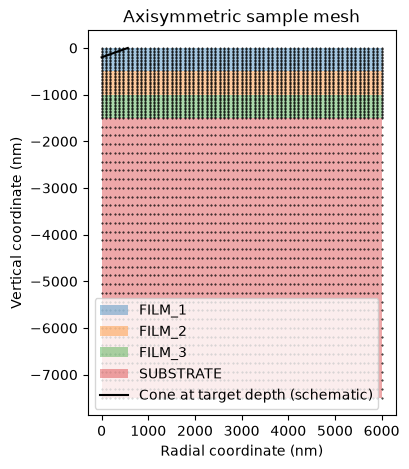

Mesh prepared. Set prepare_abapy_script = True to write the standalone generator.


In [9]:
import importlib.util
import subprocess
import sys

prepare_abapy_script = False  # Set True to write the script; no Abapy installation needed.
abapy_output = root / 'multilayer_abapy.py'  # Must not already exist.
bridge_path = root / 'matlab_code' / 'fem' / 'abapy_export.py'
bridge_spec = importlib.util.spec_from_file_location('nims_abapy', bridge_path)
bridge = importlib.util.module_from_spec(bridge_spec)
bridge_spec.loader.exec_module(bridge)
fem_films = [(layer['thickness_nm'], fitted_top_young if layer['E_GPa'] is None else layer['E_GPa'], layer['nu'])
             for layer in reversed(films)]  # Surface to substrate.
abapy_depth_nm = 200.0
abapy_mesh_size_nm = 600.0  # Indenter mesher length scale.
substrate_depth_nm, sample_width_nm = 6000.0, 6000.0
abapy_half_angle_deg = 70.3
model = bridge.build_layered_mesh(fem_films, substrate_depth_nm, sample_width_nm, 64, 16, 32)
fig, ax = plt.subplots(figsize=(7, 5))
bottom = 0.0
for name, thickness, young, nu, count in model['regions']:
    ax.fill_between([0, sample_width_nm], bottom - thickness, bottom, alpha=0.4, label=name)
    bottom -= thickness
ax.scatter([node[1] for node in model['nodes']], [node[2] for node in model['nodes']],
           s=0.2, color='black')
ax.plot([0, abapy_depth_nm * np.tan(np.deg2rad(abapy_half_angle_deg))],
        [-abapy_depth_nm, 0], 'k-', label='Cone at target depth (schematic)')
ax.set(xlabel='Radial coordinate (nm)', ylabel='Vertical coordinate (nm)', title='Axisymmetric sample mesh')
ax.set_aspect('equal')
ax.legend()
plt.show()
command = [sys.executable, str(bridge_path), '--prepare-script', '--output', str(abapy_output),
           '--young', str(substrate['E_GPa']), '--poisson', str(substrate['nu']),
           '--depth', str(abapy_depth_nm), '--mesh-size', str(abapy_mesh_size_nm),
           '--angle', str(abapy_half_angle_deg), '--substrate-depth', str(substrate_depth_nm),
           '--width', str(sample_width_nm)]
for film in fem_films:
    command.extend(['--film', *map(str, film)])
if prepare_abapy_script:
    subprocess.run(command, check=True)
else:
    print('Mesh prepared. Set prepare_abapy_script = True to write the standalone generator.')